In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy
import pandas as pd
import traceSpace as tSp

from scipy import optimize, special
from scipy import linalg
from scipy.sparse.linalg import eigsh
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags
from scipy.sparse import identity
plt.rcParams["figure.figsize"] = (12,8)

In [2]:
x_test = np.zeros(10).reshape((5,2))
print(x_test)

[[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]


In [3]:
x_test2 = np.arange(100).reshape((5,20))
x_test2_select = [item[0] for item in x_test2]
print(x_test2)
print(x_test2_select)

[[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
 [20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39]
 [40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59]
 [60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79]
 [80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99]]
[np.int64(0), np.int64(20), np.int64(40), np.int64(60), np.int64(80)]


In [4]:
leng = 10
inputdata = np.zeros(2*leng)
inputdata.reshape(leng,2)
print(inputdata)
a = np.arange(6).reshape((3, 2))
print(a)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[[0 1]
 [2 3]
 [4 5]]


In [5]:
def read_flux(flux_filename): #return flux in format of list
    filein = open(flux_filename, "r")            # Open file for reading
    inputd = filein.readlines()

    leng = len(inputd)
    print("the number of line of the txt file : " + str(flux_filename) + " list is : " + str(leng))
    inputdata = np.zeros(2*leng).reshape(leng,2)

    for i in range(0,leng):
        tokens = inputd[i].split()
        tokens = np.array(tokens, dtype=np.float64)
        #print(tokens)
        inputdata[i] = tokens

                
    return inputdata

def get_flux_val(flux, nu_E): #return flux(constant interval) at neutrino energy(interpolation)

    dE_flux = flux[1][0]-flux[0][0]
    E0_flux = flux[0][0]
    nu_E_index = int((nu_E-E0_flux)/dE_flux)
    flux_nu_E = 0
    if(nu_E<flux[-1][0]):
        flux_nu_E = flux[nu_E_index+1][1]*(nu_E-flux[nu_E_index][0])+flux[nu_E_index][1]*(flux[nu_E_index+1][0]-nu_E)
        flux_nu_E = flux_nu_E/(flux[nu_E_index+1][0]-flux[nu_E_index][0])
    
    else:
        flux_nu_E=0

    return flux_nu_E*1e-4 #1e-4 for m^2->cm^2 conversion

def get_flux_val_vect(flux, nu_E_lst):
    flux_val_lst = np.zeros(len(nu_E_lst))
    for i in range(0, len(flux_val_lst)):
        flux_val_lst[i] = get_flux_val(flux, nu_E_lst[i])
    return flux_val_lst

def get_flux_avg(flux):
    avg = 0
    total_flux = 0
    for i in range(0,len(flux)):
        avg = avg + flux[i][0]*flux[i][1]
        total_flux = total_flux + flux[i][1]
        
    avg = avg/total_flux
    
    return avg

def merge_bins(flux,merge_bin):#merge_bin : how many bins to merge to 1 bin ex if merge_bin=2 merge 2 bins into 2
    leng = len(flux)
    print("original flux bin number : "+str(leng))
    div_or_not = 0
    if(leng%merge_bin == 0):
        bin_merged_flux_leng = int(leng/merge_bin)
        div_or_not = 0
    else:
        bin_merged_flux_leng = int(leng/merge_bin) + 1 #make one more bin for leftover
        div_or_not = 1
    print("new bin merged flux bin number : "+str(bin_merged_flux_leng))
    bin_merged_flux = np.zeros(2*bin_merged_flux_leng).reshape((bin_merged_flux_leng, 2))
    
    nu_E_avg = 0
    bin_flux_avg = 0
    for i in range(0,bin_merged_flux_leng-1):
        for j in range(0,merge_bin):
            nu_E_avg = nu_E_avg + flux[i*merge_bin+j][0]
            bin_flux_avg = bin_flux_avg + flux[i*merge_bin+j][1]
        nu_E_avg = nu_E_avg/merge_bin
        bin_flux_avg = bin_flux_avg/merge_bin
        bin_merged_flux[i][0] = nu_E_avg
        bin_merged_flux[i][1] = bin_flux_avg
        nu_E_avg = 0
        bin_flux_avg = 0
        
    left_over_bin_num = 0
    for i in range(0,leng-merge_bin*(bin_merged_flux_leng-1)):#fill the last bin
        nu_E_avg = nu_E_avg + flux[merge_bin*(bin_merged_flux_leng-1)+i][0]
        bin_flux_avg = bin_flux_avg + flux[merge_bin*(bin_merged_flux_leng-1)+i][1]
        left_over_bin_num = left_over_bin_num + 1
        
    nu_E_avg = nu_E_avg/left_over_bin_num
    bin_flux_avg = bin_flux_avg/left_over_bin_num
    bin_merged_flux[-1][0] = nu_E_avg
    bin_merged_flux[-1][1] = bin_flux_avg
    
    return bin_merged_flux

def bin_dif_RMS(target_flux, fit_flux):
    dif_RMS = 0
    for i in range(0,len(target_flux)):
        dif_RMS = dif_RMS + (target_flux[i][1]-get_flux_val(fit_flux, target_flux[i][0]))**2
        
    dif_RMS = dif_RMS/len(target_flux)
    dif_RMS = dif_RMS**0.5
    return dif_RMS

def chi_2_hist(target_flux, fit_flux, flux_uncertainty):
    chi_2 = 0
    for i in range(0,len(target_flux)):
        if not(target_flux[i][1]==0):
            chi_2 = chi_2 + (target_flux[i][1]-get_flux_val(fit_flux, target_flux[i][0]))**2/(target_flux[i][1]+(flux_uncertainty*target_flux[i][1])**2)
        
    return chi_2

In [6]:
nuFlux1p52_flux = read_flux("nuSTORM_flux_txt_files/nuFlux1p52_nue.txt")
nuFlux2p0_flux = read_flux("nuSTORM_flux_txt_files/nuFlux2p0_nue.txt")
nuFlux3p04_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p04_nue.txt")
nuFlux3p8_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p8_nue.txt")
nuFlux4p56_flux = read_flux("nuSTORM_flux_txt_files/nuFlux4p56_nue.txt")
nuFlux5p47_flux = read_flux("nuSTORM_flux_txt_files/nuFlux5p47_nue.txt")

nuFlux1p52_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux1p52_numu.txt")
nuFlux2p0_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux2p0_numu.txt")
nuFlux3p04_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p04_numu.txt")
nuFlux3p8_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux3p8_numu.txt")
nuFlux4p56_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux4p56_numu.txt")
nuFlux5p47_numu_flux = read_flux("nuSTORM_flux_txt_files/nuFlux5p47_numu.txt")

PiFlash1p52_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash1p52_numu.txt")
PiFlash2p0_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash2p00_numu.txt")
PiFlash3p04_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash3p04_numu.txt")
PiFlash3p8_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash3p80_numu.txt")
PiFlash4p56_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash4p56_numu.txt")
PiFlash5p47_flux = read_flux("nuSTORM_flux_txt_files/nuFluxPiFlash5p47_numu.txt")

nuSTORM_flux_lst = [nuFlux1p52_flux, nuFlux2p0_flux, nuFlux3p04_flux, nuFlux3p8_flux, nuFlux4p56_flux, nuFlux5p47_flux]
nuSTORM_PiFlash_lst = [PiFlash1p52_flux, PiFlash2p0_flux, PiFlash3p04_flux, PiFlash3p8_flux, PiFlash4p56_flux, PiFlash5p47_flux]
E_lst = ['1.52GeV', '2GeV', '3.04GeV', '3.8GeV', '4.56GeV', '5.47GeV']

target_flux = read_flux("nuSTORM_flux_txt_files/T2K_ND280_250kA-nue.dat")
target_anti_nue_flux = read_flux("nuSTORM_flux_txt_files/T2K_ND280_250kA-anue.dat")

DUNE_nue_numode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_numode.dat")
DUNE_nue_antinumode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_antinumode.dat")

print(get_flux_val(nuFlux4p56_flux, 3.5))

the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux1p52_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux2p0_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p04_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p8_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux4p56_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux5p47_nue.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux1p52_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux2p0_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p04_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux3p8_numu.txt list is : 120
the number of line of the txt file : nuSTORM_flux_txt_files/nuFlux4p56

In [7]:
bin_merge_num = 2

nuFlux1p52_flux_merged = merge_bins(nuFlux1p52_flux, bin_merge_num)
nuFlux2p0_flux_merged = merge_bins(nuFlux2p0_flux, bin_merge_num)
nuFlux3p04_flux_merged = merge_bins(nuFlux3p04_flux, bin_merge_num)
nuFlux3p8_flux_merged = merge_bins(nuFlux3p8_flux, bin_merge_num)
nuFlux4p56_flux_merged = merge_bins(nuFlux4p56_flux, bin_merge_num)
nuFlux5p47_flux_merged = merge_bins(nuFlux5p47_flux, bin_merge_num)

nuSTORM_flux_lst_merged = [nuFlux1p52_flux_merged, nuFlux2p0_flux_merged, nuFlux3p04_flux_merged, nuFlux3p8_flux_merged, nuFlux4p56_flux_merged, nuFlux5p47_flux_merged]

original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60


In [8]:
def sum_flux_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    return coeff_1p52*get_flux_val_vect(nuFlux1p52_flux, nu_E) + coeff_2p0*get_flux_val_vect(nuFlux2p0_flux, nu_E) + coeff_3p04*get_flux_val_vect(nuFlux3p04_flux, nu_E) + coeff_3p8*get_flux_val_vect(nuFlux3p8_flux, nu_E) + coeff_4p56*get_flux_val_vect(nuFlux4p56_flux, nu_E) + coeff_5p47*get_flux_val_vect(nuFlux5p47_flux, nu_E)
    
def sum_PiFlash_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8 , coeff_4p56, coeff_5p47):
    return coeff_1p52*get_flux_val_vect(PiFlash1p52_flux, nu_E) + coeff_2p0*get_flux_val_vect(PiFlash2p0_flux, nu_E) + coeff_3p04*get_flux_val_vect(PiFlash3p04_flux, nu_E) + coeff_3p8*get_flux_val_vect(PiFlash3p8_flux, nu_E) + coeff_4p56*get_flux_val_vect(PiFlash4p56_flux, nu_E) + coeff_5p47*get_flux_val_vect(PiFlash5p47_flux, nu_E)
   

sum_PiFlash_nu_E([1,2,3,4,5,6,7,8], 0.16, 0.16, 0.16, 0.16, 0.16, 0.16)

array([2.08623689e+12, 7.96436109e+11, 1.17531644e+11, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00])

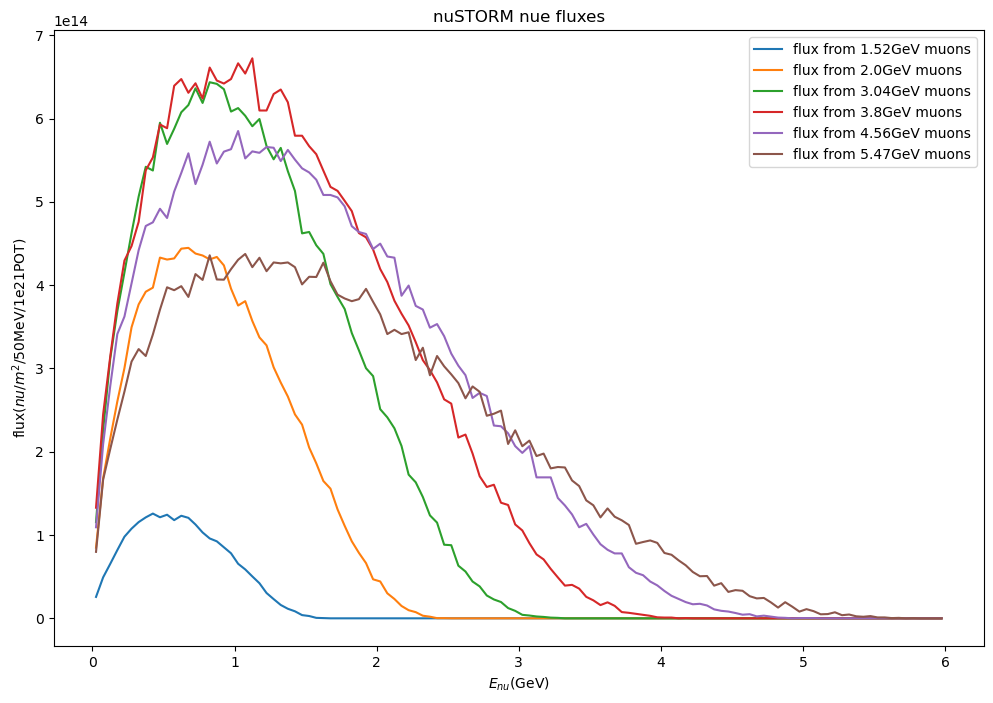

In [9]:
plt.plot(nuFlux1p52_flux[:,0], nuFlux1p52_flux[:,1],label='flux from 1.52GeV muons')
plt.plot(nuFlux2p0_flux[:,0], nuFlux2p0_flux[:,1],label='flux from 2.0GeV muons')
plt.plot(nuFlux3p04_flux[:,0], nuFlux3p04_flux[:,1],label='flux from 3.04GeV muons')
plt.plot(nuFlux3p8_flux[:,0], nuFlux3p8_flux[:,1],label='flux from 3.8GeV muons')
plt.plot(nuFlux4p56_flux[:,0], nuFlux4p56_flux[:,1],label='flux from 4.56GeV muons')
plt.plot(nuFlux5p47_flux[:,0], nuFlux5p47_flux[:,1],label='flux from 5.47GeV muons')

plt.title("nuSTORM nue fluxes")
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux(${nu}$/$m^2$/50MeV/1e21POT)")
plt.legend()
plt.show()

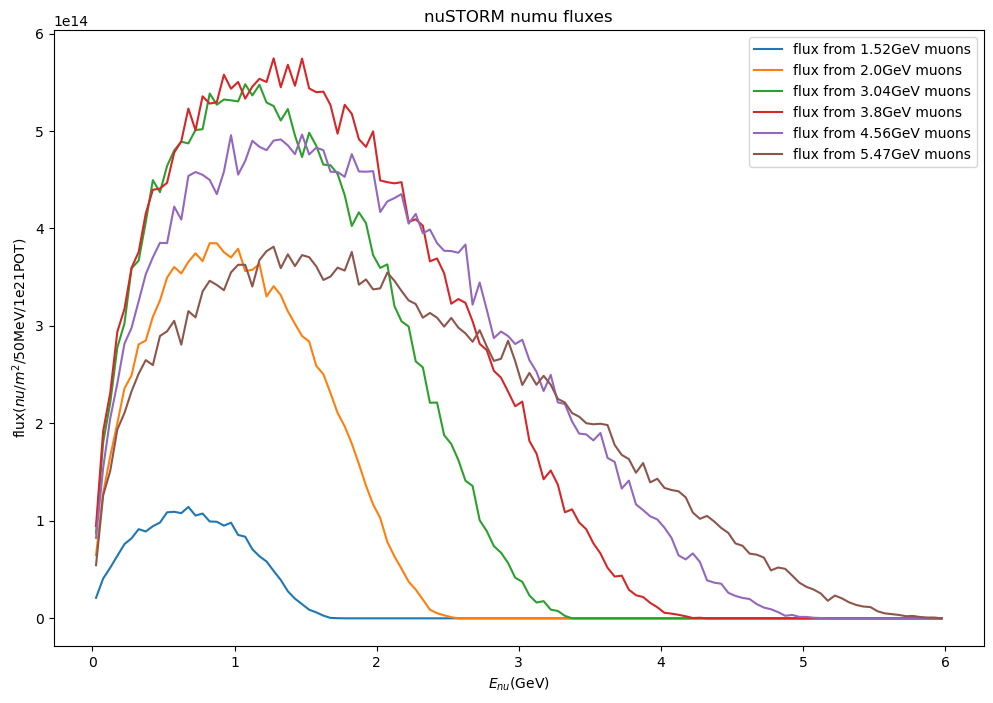

In [10]:
plt.plot(nuFlux1p52_numu_flux[:,0], nuFlux1p52_numu_flux[:,1],label='flux from 1.52GeV muons')
plt.plot(nuFlux2p0_numu_flux[:,0], nuFlux2p0_numu_flux[:,1],label='flux from 2.0GeV muons')
plt.plot(nuFlux3p04_numu_flux[:,0], nuFlux3p04_numu_flux[:,1],label='flux from 3.04GeV muons')
plt.plot(nuFlux3p8_numu_flux[:,0], nuFlux3p8_numu_flux[:,1],label='flux from 3.8GeV muons')
plt.plot(nuFlux4p56_numu_flux[:,0], nuFlux4p56_numu_flux[:,1],label='flux from 4.56GeV muons')
plt.plot(nuFlux5p47_numu_flux[:,0], nuFlux5p47_numu_flux[:,1],label='flux from 5.47GeV muons')

plt.title("nuSTORM numu fluxes")
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux(${nu}$/$m^2$/50MeV/1e21POT)")
plt.legend()
plt.show()

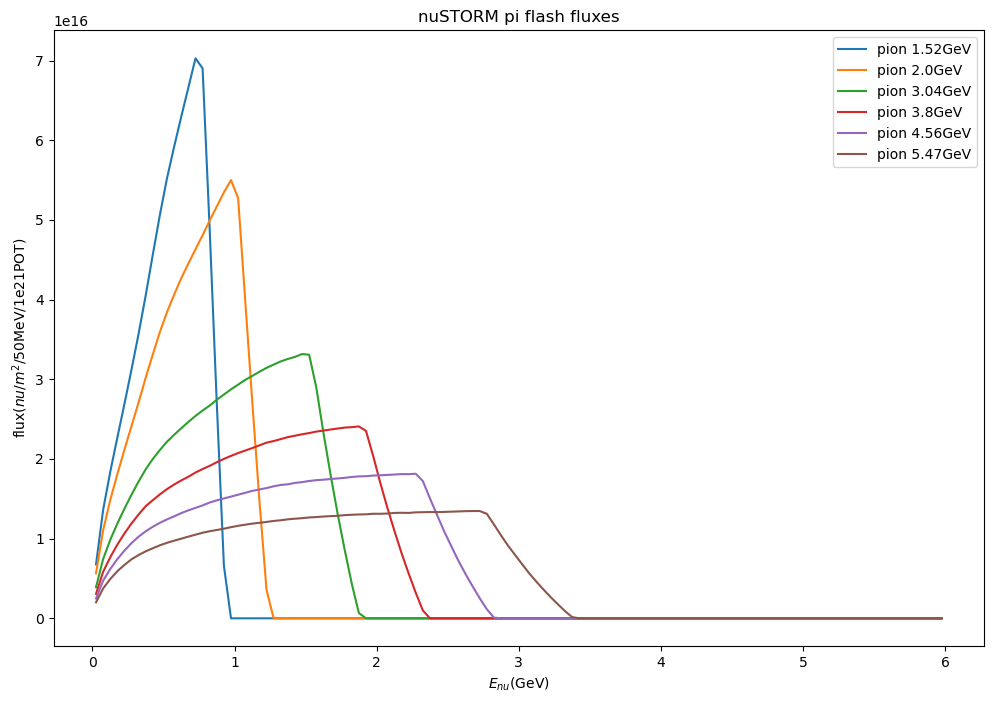

In [11]:

plt.plot(PiFlash1p52_flux[:,0], PiFlash1p52_flux[:,1],label='pion 1.52GeV')
plt.plot(PiFlash2p0_flux[:,0], PiFlash2p0_flux[:,1],label='pion 2.0GeV')
plt.plot(PiFlash3p04_flux[:,0], PiFlash3p04_flux[:,1],label='pion 3.04GeV')
plt.plot(PiFlash3p8_flux[:,0], PiFlash3p8_flux[:,1],label='pion 3.8GeV')
plt.plot(PiFlash4p56_flux[:,0], PiFlash4p56_flux[:,1],label='pion 4.56GeV')
plt.plot(PiFlash5p47_flux[:,0], PiFlash5p47_flux[:,1],label='pion 5.47GeV')

plt.title("nuSTORM pi flash fluxes")
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux(${nu}$/$m^2$/50MeV/1e21POT)")
plt.legend()
plt.show()

[6.025e+00 8.650e+07]


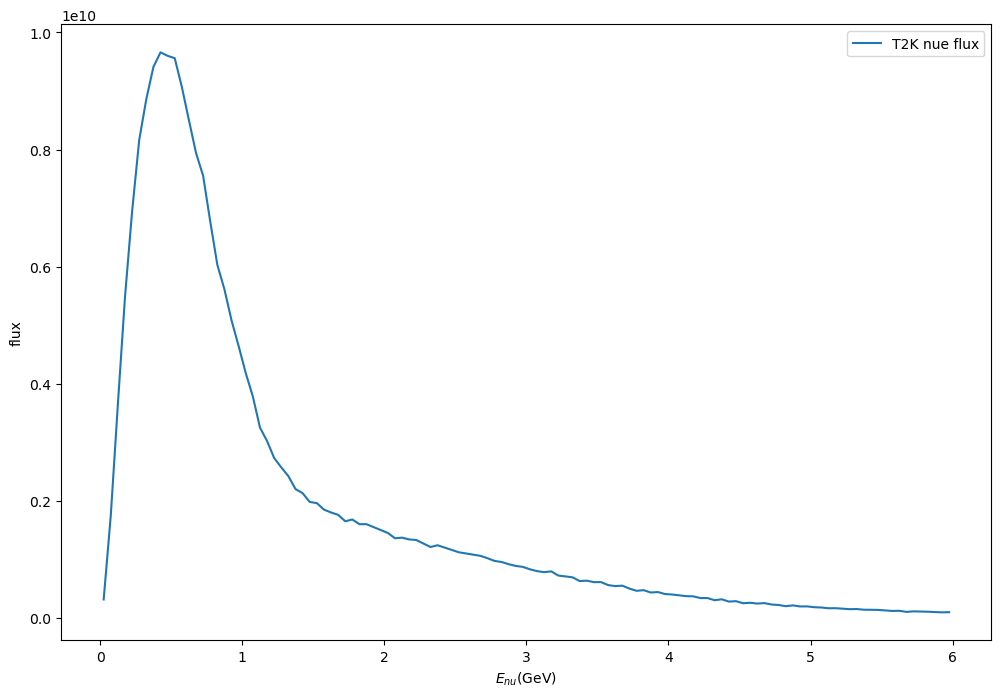

In [12]:
print(target_flux[120])
target_flux = target_flux[:120]
plt.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
plt.xlabel("$E_{nu}$(GeV)")
plt.ylabel("flux")
plt.legend()
plt.show()

In [13]:
sigma_array = np.zeros(len(target_flux[:,1]))
sigma_array = target_flux[:,1]**0.5#+0.1*target_flux[:,1]
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1

sigma_array = 1
pars, cov=optimize.curve_fit(sum_flux_nu_E, target_flux[:,0], target_flux[:,1], p0=[ 7.39545089e-01,-9.27494391e-02, 5.51358513e-02,-2.79184563e-02, -6.00695425e-04, 4.93489427e-02],method='lm',sigma=sigma_array,maxfev=2500) #fit
print("coeff is : "+np.array2string(pars, separator=","))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))
print("Uncertainty % is : "+str(100*np.sqrt(cov.diagonal())/pars))

coeff is : [ 7.39545089e-01,-9.27494391e-02, 5.51358513e-02,-2.79184563e-02,
 -6.00695425e-04, 4.93489427e-02]
Uncertainty is : [0.03739521 0.02625632 0.02787999 0.02978439 0.0323554  0.02076357]
Uncertainty % is : [ 5.05651497e+00 -2.83088746e+01  5.05659894e+01 -1.06683528e+02
 -5.38632304e+03  4.20750135e+01]


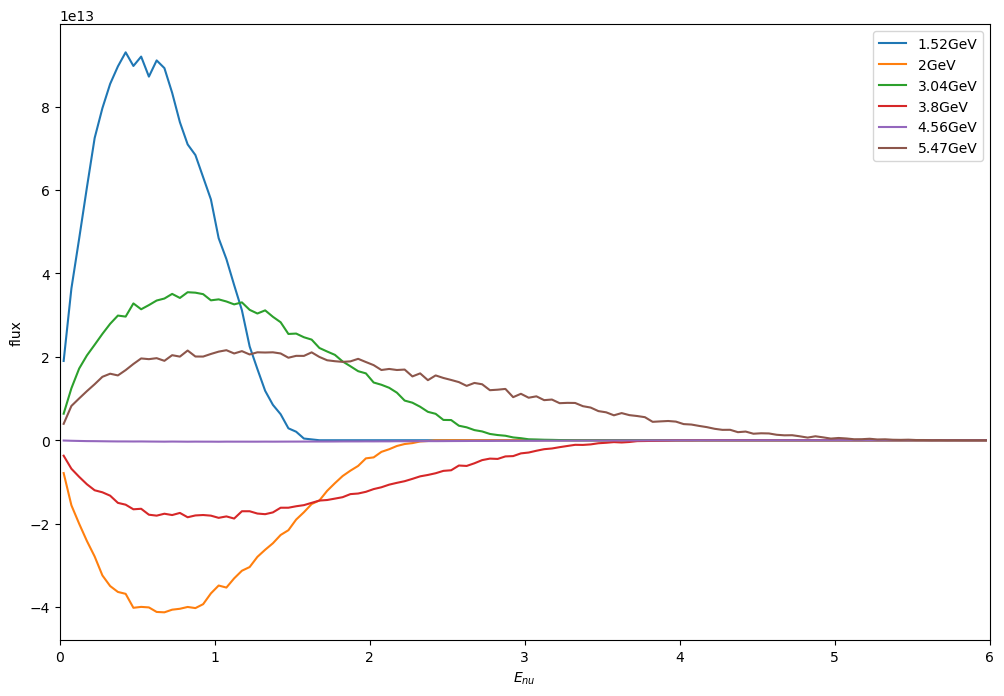

In [14]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [ 7.39545089e-01 -9.27494391e-02  5.51358513e-02 -2.79184563e-02
 -6.00695425e-04  4.93489427e-02]
Uncertainty is : [0.03739521 0.02625632 0.02787999 0.02978439 0.0323554  0.02076357]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.1461675219170184 GeV
chi^2 of bin diff : 1.1998E+04


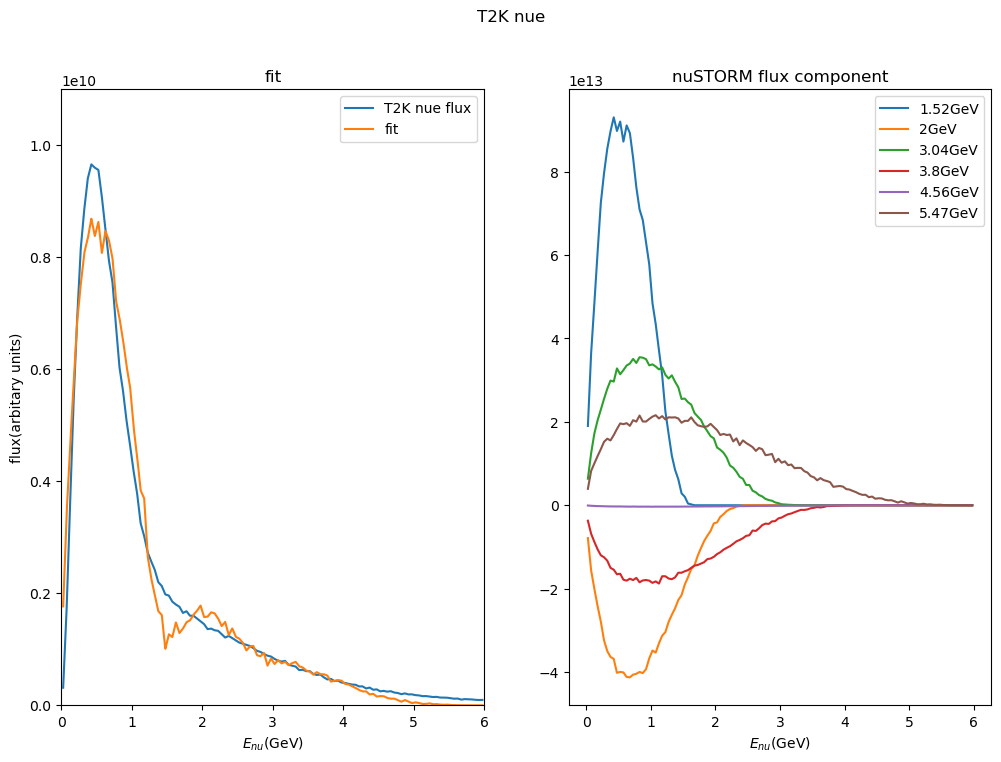

In [15]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *pars) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux(arbitary units)')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()

In [16]:
#sum_PiFlash_nu_E

sigma_array = np.zeros(len(target_flux[:,1]))
sigma_array = target_flux[:,1]**0.5#+0.1*target_flux[:,1]
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1

#sigma_array = 1
pars, cov=optimize.curve_fit(sum_PiFlash_nu_E, target_flux[:,0], target_flux[:,1], p0=[ 7.39545089e-01,-9.27494391e-02, 5.51358513e-02,-2.79184563e-02, -6.00695425e-04, 4.93489427e-02],method='lm',sigma=sigma_array,maxfev=2500) #fit
print("coeff is : "+np.array2string(pars, separator=","))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))
print("Uncertainty % is : "+str(100*np.sqrt(cov.diagonal())/pars))

coeff is : [ 8.33801924e-04, 4.34123704e-04, 2.24488973e-04, 1.62499377e-04,
 -5.26742998e-05, 9.42139601e-04]
Uncertainty is : [0.00010507 0.00011116 0.00012104 0.00017944 0.0002117  0.00015545]
Uncertainty % is : [  12.60101351   25.6062797    53.91632939  110.42287118 -401.90173454
   16.49960833]


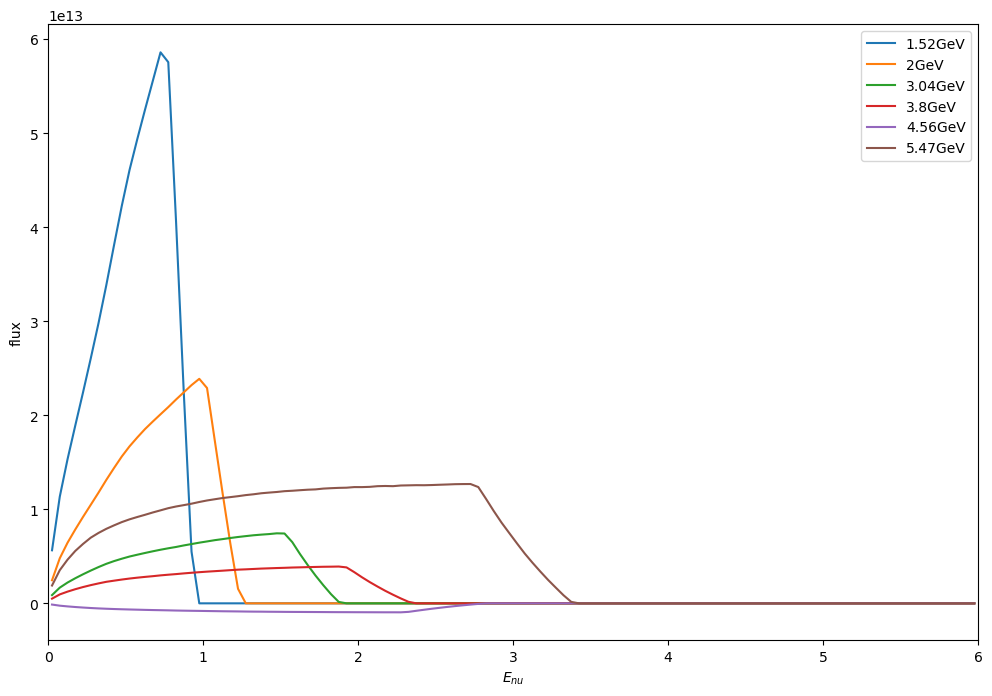

In [17]:
for i in range(0, len(nuSTORM_PiFlash_lst)):
    plt.plot(nuSTORM_PiFlash_lst[i][:,0], nuSTORM_PiFlash_lst[i][:,1]*pars[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [ 8.33801924e-04  4.34123704e-04  2.24488973e-04  1.62499377e-04
 -5.26742998e-05  9.42139601e-04]
Uncertainty is : [0.00010507 0.00011116 0.00012104 0.00017944 0.0002117  0.00015545]
target flux $E_{nu}$ avg : 1.2212504643814395 GeV fit flux $E_{nu}$ avg : 1.0407754184793199 GeV
chi^2 of bin diff : 1.1999E+04


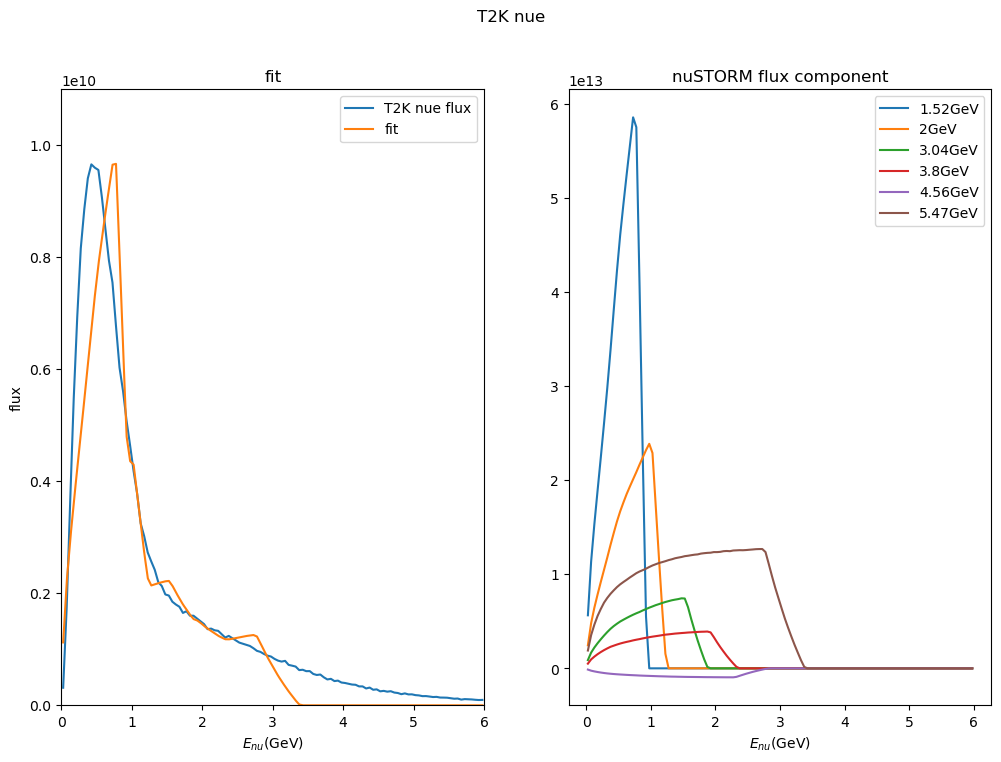

In [18]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_PiFlash_nu_E(fx, *pars) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = chi_2_hist(target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

plt.rcParams["figure.figsize"] = (12,8)
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_flux[:,0], target_flux[:,1],label='T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_PiFlash_lst)):
    ax2.plot(nuSTORM_PiFlash_lst[i][:,0], nuSTORM_PiFlash_lst[i][:,1]*pars[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1.1e10)
ax1.legend()
ax2.legend()
plt.show()  

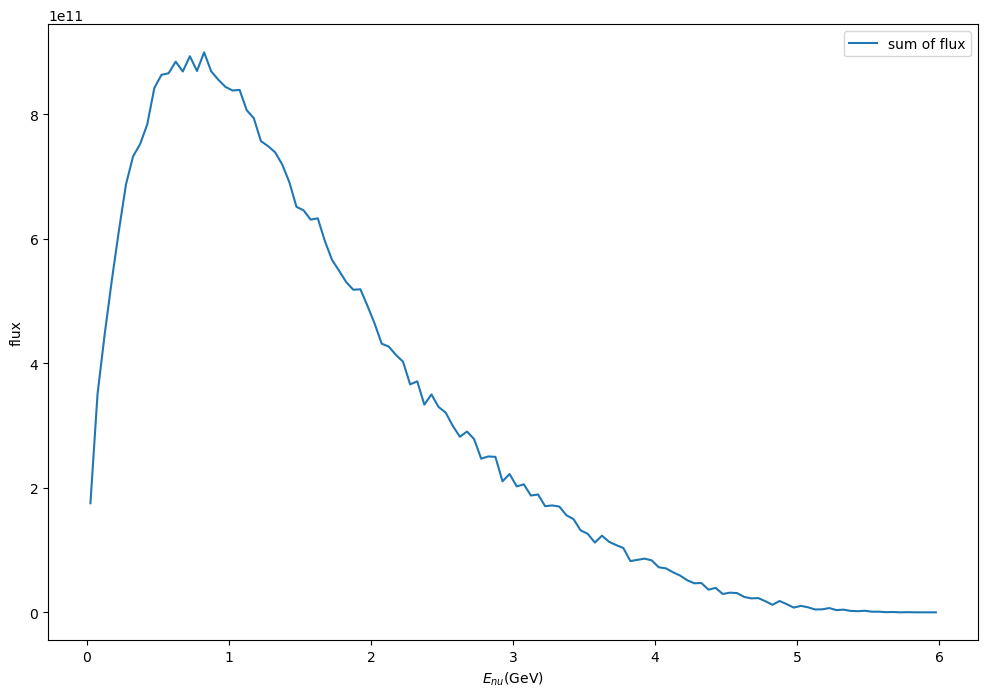

In [19]:
sum_flux = np.zeros(2*len(nuSTORM_flux_lst[0])).reshape((len(nuSTORM_flux_lst[0]),2))

for i in range(0, len(nuSTORM_flux_lst[0])):
    sum_flux[i][0] = nuSTORM_flux_lst[0][i][0]
    for j in range(0,len(pars)):
        sum_flux[i][1] = sum_flux[i][1] + nuSTORM_flux_lst[j][i][1]*pars[j]
        
plt.plot(sum_flux[:,0], sum_flux[:,1],label='sum of flux')
plt.xlabel('$E_{nu}$(GeV)')
plt.ylabel('flux')
plt.legend()

plt.show()

In [20]:
sigma_array = np.zeros(len(target_anti_nue_flux[:,1]))
sigma_array = target_anti_nue_flux[:,1]**0.5
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
#sigma_array = 1
pars_anti_nue, cov_anti_nue=optimize.curve_fit(sum_flux_nu_E, target_anti_nue_flux[:,0], target_anti_nue_flux[:,1], p0=[1/6, 1/6, 1/6, 1/6, 1/6, 1/6],sigma=sigma_array) #fits the whole range with a function with 3 peaks
print("coeff is : "+str(pars_anti_nue))
print("Uncertainty is : "+str(np.sqrt(cov_anti_nue.diagonal())))

coeff is : [ 0.49493527 -0.02990246  0.02378308 -0.00711168 -0.00839069  0.02552103]
Uncertainty is : [0.02542788 0.01264267 0.01202516 0.01270482 0.01180107 0.00614756]


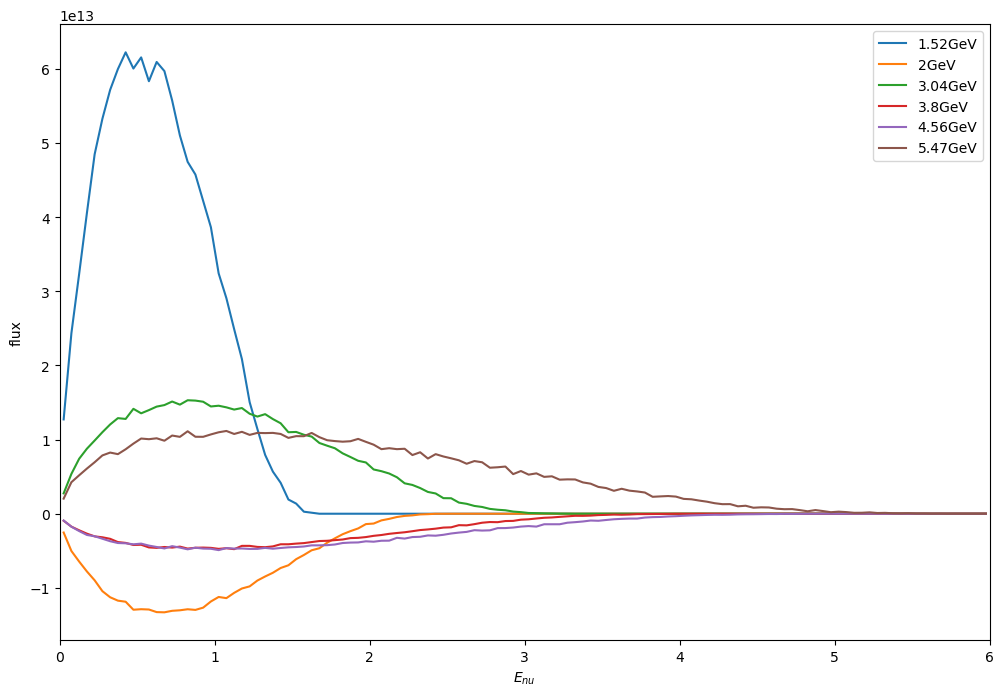

In [21]:
for i in range(0, len(nuSTORM_flux_lst)):
    plt.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars_anti_nue[i],label=E_lst[i])
    
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

coeff is : [ 0.49493527 -0.02990246  0.02378308 -0.00711168 -0.00839069  0.02552103]
Uncertainty is : [0.02542788 0.01264267 0.01202516 0.01270482 0.01180107 0.00614756]
target flux $E_{nu}$ avg : 0.9956615351395163 GeV fit flux $E_{nu}$ avg : 0.9792669279681123 GeV
RMS of bin diff : 1.8972E+09
chi^2 of bin diff : 2.0397E+04


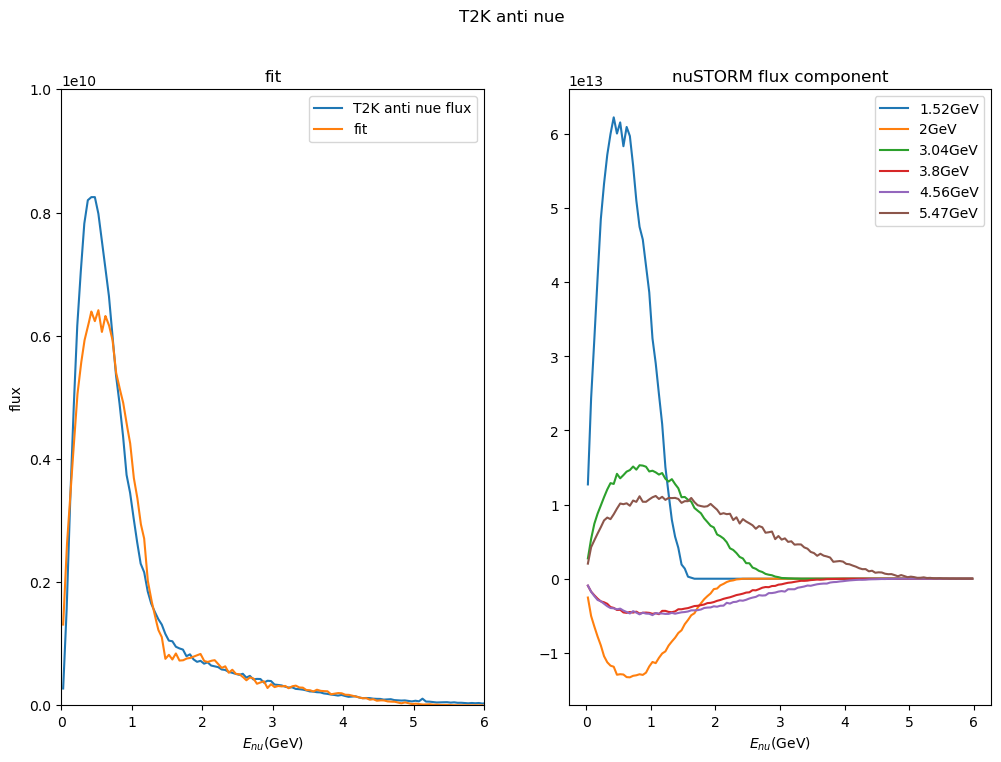

In [22]:
fit_lst_leng = 5000
fx = np.linspace(target_flux[:,0][0], target_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *pars_anti_nue) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(target_anti_nue_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars_anti_nue))
print("Uncertainty is : "+str(np.sqrt(cov_anti_nue.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

anti_nue_diff = bin_dif_RMS(target_anti_nue_flux, fit_flux)
print("RMS of bin diff : "+str("{0:.4E}".format(anti_nue_diff)))

nue_diff = chi_2_hist(target_anti_nue_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K anti nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(target_anti_nue_flux[:,0], target_anti_nue_flux[:,1],label='T2K anti nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars_anti_nue[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1e10)
ax1.legend()
ax2.legend()
plt.show()

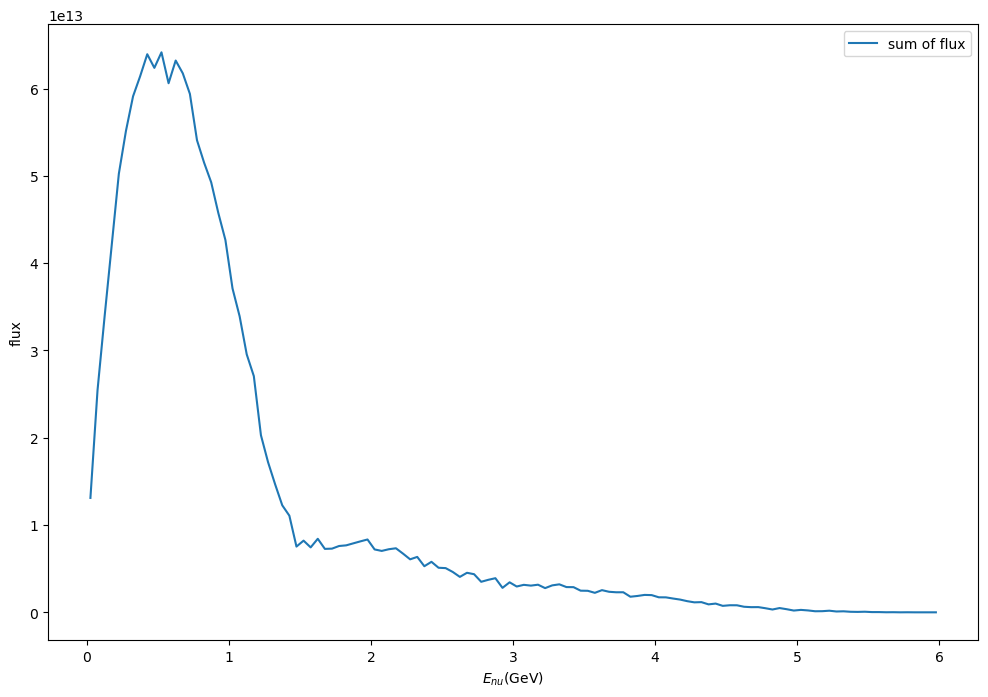

In [23]:
sum_flux = np.zeros(2*len(nuSTORM_flux_lst[0])).reshape((len(nuSTORM_flux_lst[0]),2))

for i in range(0, len(nuSTORM_flux_lst[0])):
    sum_flux[i][0] = nuSTORM_flux_lst[0][i][0]
    for j in range(0,len(pars)):
        sum_flux[i][1] = sum_flux[i][1] + nuSTORM_flux_lst[j][i][1]*pars_anti_nue[j]
        
plt.plot(sum_flux[:,0], sum_flux[:,1],label='sum of flux')
plt.xlabel('$E_{nu}$(GeV)')
plt.ylabel('flux')
plt.legend()

plt.show()

In [24]:
bin_merge_num = 2

nuFlux1p52_flux_merged = merge_bins(nuFlux1p52_flux, bin_merge_num)
nuFlux2p0_flux_merged = merge_bins(nuFlux2p0_flux, bin_merge_num)
nuFlux3p04_flux_merged = merge_bins(nuFlux3p04_flux, bin_merge_num)
nuFlux3p8_flux_merged = merge_bins(nuFlux3p8_flux, bin_merge_num)
nuFlux4p56_flux_merged = merge_bins(nuFlux4p56_flux, bin_merge_num)
nuFlux5p47_flux_merged = merge_bins(nuFlux5p47_flux, bin_merge_num)

nuSTORM_flux_lst_merged = [nuFlux1p52_flux_merged, nuFlux2p0_flux_merged, nuFlux3p04_flux_merged, nuFlux3p8_flux_merged, nuFlux4p56_flux_merged, nuFlux5p47_flux_merged]

original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60
original flux bin number : 120
new bin merged flux bin number : 60


In [25]:
def sum_merged_flux_nu_E(nu_E, coeff_1p52, coeff_2p0, coeff_3p04, coeff_3p8, coeff_4p56, coeff_5p47):
    return coeff_1p52*get_flux_val_vect(nuFlux1p52_flux_merged, nu_E) + coeff_2p0*get_flux_val_vect(nuFlux1p52_flux_merged, nu_E) + coeff_3p04*get_flux_val_vect(nuFlux3p04_flux_merged, nu_E) + coeff_3p8*get_flux_val_vect(nuFlux3p8_flux_merged, nu_E) + coeff_4p56*get_flux_val_vect(nuFlux4p56_flux_merged, nu_E) + coeff_5p47*get_flux_val_vect(nuFlux5p47_flux_merged, nu_E)

print(sum_merged_flux_nu_E([1,2,3,4,5,6,7,8], 0.16, 0.16, 0.16, 0.16, 0.16, 0.16))
print(pars_merged)
print(sum_merged_flux_nu_E([1,2,3,4,5,6,7,8],*pars_merged))

[3.83956078e+10 2.43093769e+10 8.65016362e+09 1.95388625e+09
 1.70087369e+08 0.00000000e+00 0.00000000e+00 0.00000000e+00]


NameError: name 'pars_merged' is not defined

original flux bin number : 120
new bin merged flux bin number : 60


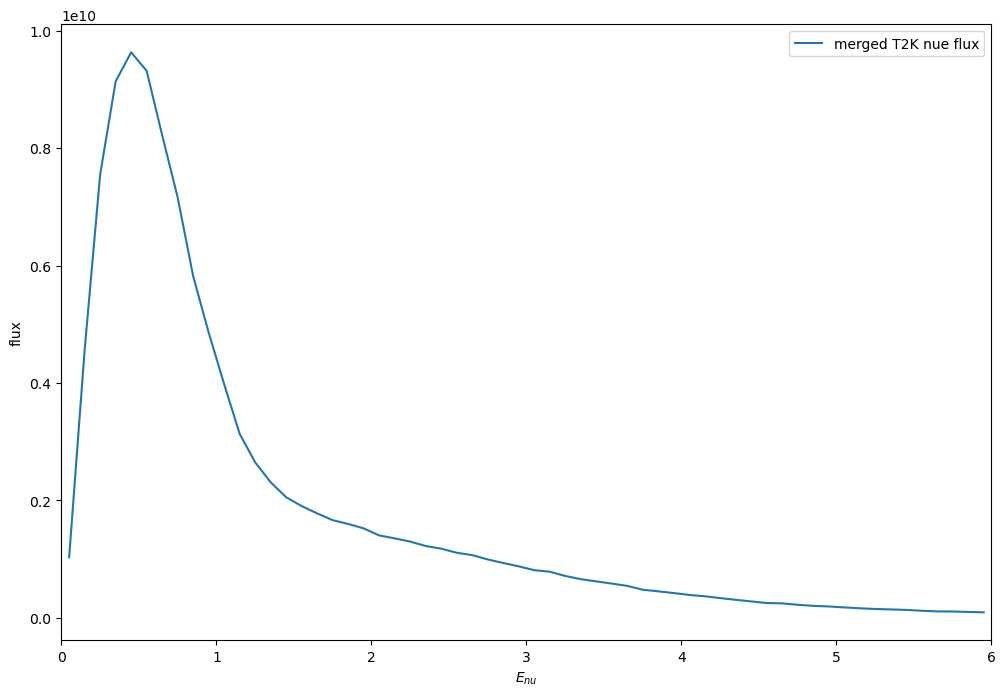

In [26]:
merged_target_flux = merge_bins(target_flux,2)
plt.plot(merged_target_flux[:,0], merged_target_flux[:,1],label='merged T2K nue flux')
plt.xlim(0,6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

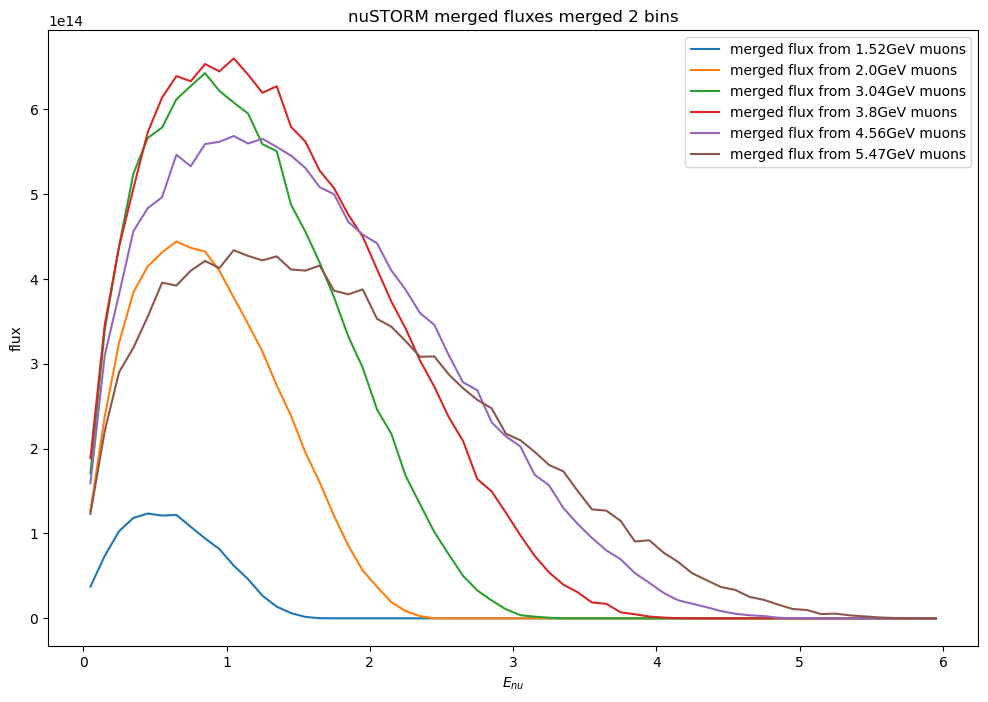

In [27]:
plt.plot(nuFlux1p52_flux_merged[:,0], nuFlux1p52_flux_merged[:,1],label='merged flux from 1.52GeV muons')
plt.plot(nuFlux2p0_flux_merged[:,0], nuFlux2p0_flux_merged[:,1],label='merged flux from 2.0GeV muons')
plt.plot(nuFlux3p04_flux_merged[:,0], nuFlux3p04_flux_merged[:,1],label='merged flux from 3.04GeV muons')
plt.plot(nuFlux3p8_flux_merged[:,0], nuFlux3p8_flux_merged[:,1],label='merged flux from 3.8GeV muons')
plt.plot(nuFlux4p56_flux_merged[:,0], nuFlux4p56_flux_merged[:,1],label='merged flux from 4.56GeV muons')
plt.plot(nuFlux5p47_flux_merged[:,0], nuFlux5p47_flux_merged[:,1],label='merged flux from 5.47GeV muons')

plt.title("nuSTORM merged fluxes merged "+str(bin_merge_num)+" bins")
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

In [28]:
sigma_array = np.zeros(len(merged_target_flux[:,1]))
sigma_array = merged_target_flux[:,1]**0.5
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
#sigma_array = 1
pars_merged, cov_merged=optimize.curve_fit(sum_merged_flux_nu_E, merged_target_flux[:,0], merged_target_flux[:,1], p0=[1/6, 1/6, 1/6, 1/6, 1/6, 1/6],sigma=sigma_array) #fits the whole range with a function with 3 peaks
print("coeff is : "+str(pars_merged))
print("Uncertainty is : "+str(np.sqrt(cov_merged.diagonal())))

coeff is : [ 2.72492397e+02 -2.71978853e+02 -1.00382470e-02  3.34554724e-02
 -6.10645177e-02  8.11237749e-02]
Uncertainty is : [3.91221602e+06 3.91221605e+06 1.87519599e-02 3.36352090e-02
 3.65632130e-02 1.96125192e-02]


coeff is : [ 2.72492397e+02 -2.71978853e+02 -1.00382470e-02  3.34554724e-02
 -6.10645177e-02  8.11237749e-02]
Uncertainty is : [3.91221602e+06 3.91221605e+06 1.87519599e-02 3.36352090e-02
 3.65632130e-02 1.96125192e-02]
target flux $E_{nu}$ avg : 1.2212149383610662 GeV fit flux $E_{nu}$ avg : 1.2164537531534982 GeV
RMS of bin diff : 3.1440E+09
chi^2 of bin diff : 5.9990E+03


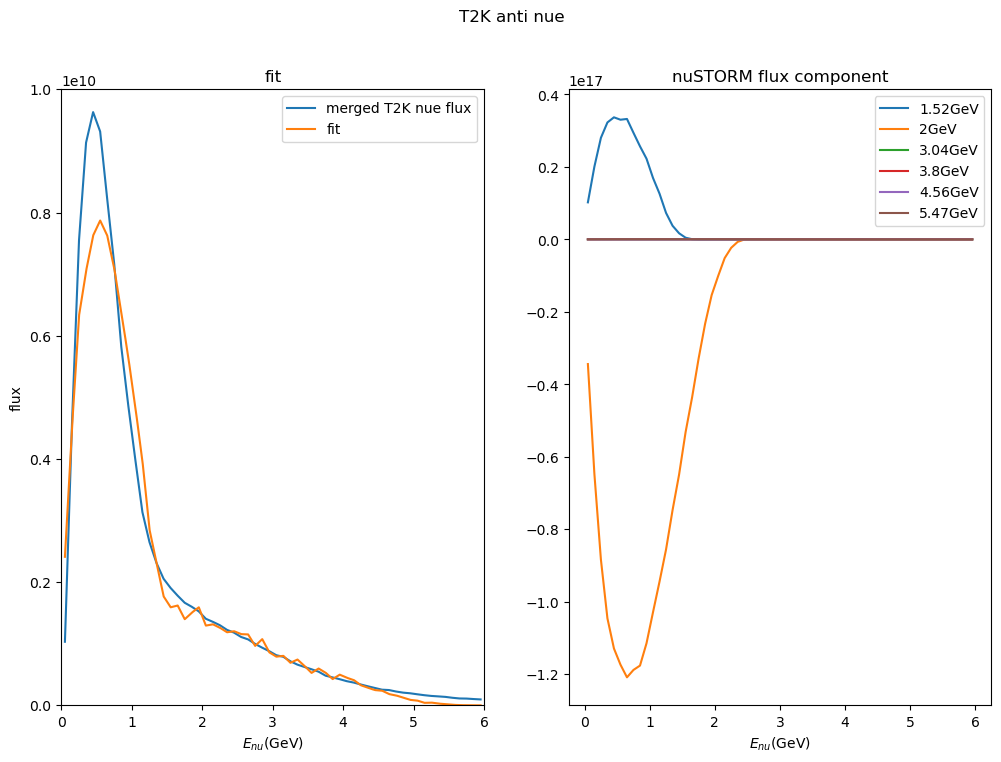

In [29]:
fit_lst_leng = 5000
fx = np.linspace(merged_target_flux[:,0][0], merged_target_flux[:,0][-1], fit_lst_leng)
fy = sum_merged_flux_nu_E(fx, *pars_merged) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(merged_target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars_merged))
print("Uncertainty is : "+str(np.sqrt(cov_merged.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

merged_nue_diff = bin_dif_RMS(merged_target_flux, fit_flux)
print("RMS of bin diff : "+str("{0:.4E}".format(merged_nue_diff)))

nue_diff = chi_2_hist(merged_target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('T2K anti nue')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(merged_target_flux[:,0], merged_target_flux[:,1],label='merged T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst_merged[i][:,0], nuSTORM_flux_lst_merged[i][:,1]*pars_merged[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1e10)
ax1.legend()
ax2.legend()
plt.show()


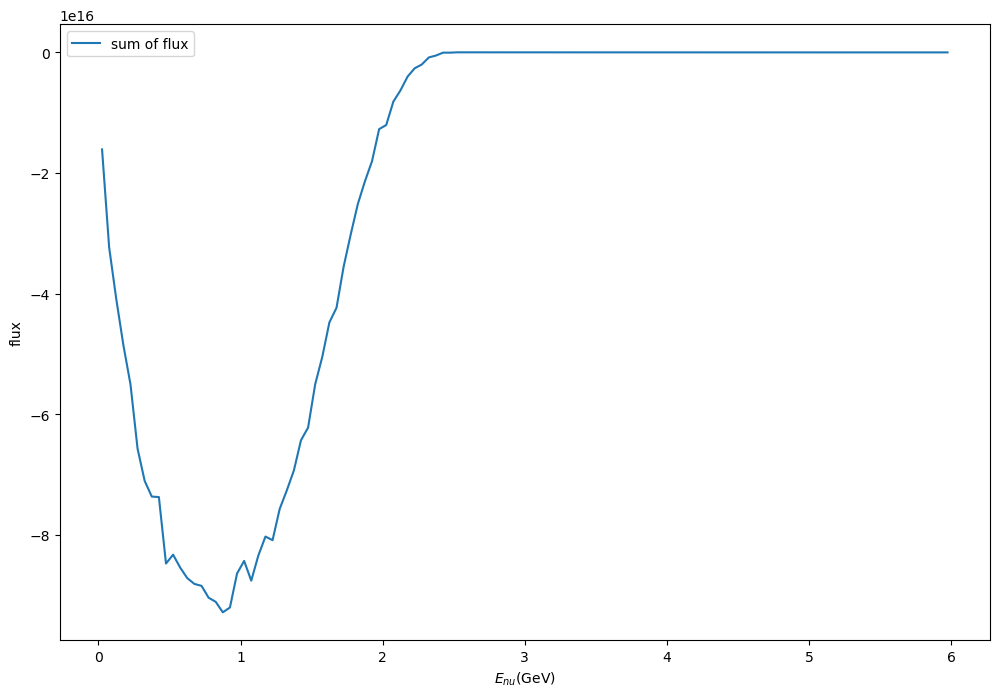

In [30]:
sum_flux = np.zeros(2*len(nuSTORM_flux_lst[0])).reshape((len(nuSTORM_flux_lst[0]),2))

for i in range(0, len(nuSTORM_flux_lst[0])):
    sum_flux[i][0] = nuSTORM_flux_lst[0][i][0]
    for j in range(0,len(pars)):
        sum_flux[i][1] = sum_flux[i][1] + nuSTORM_flux_lst[j][i][1]*pars_merged[j]
        
plt.plot(sum_flux[:,0], sum_flux[:,1],label='sum of flux')
plt.xlabel('$E_{nu}$(GeV)')
plt.ylabel('flux')
plt.legend()

plt.show()

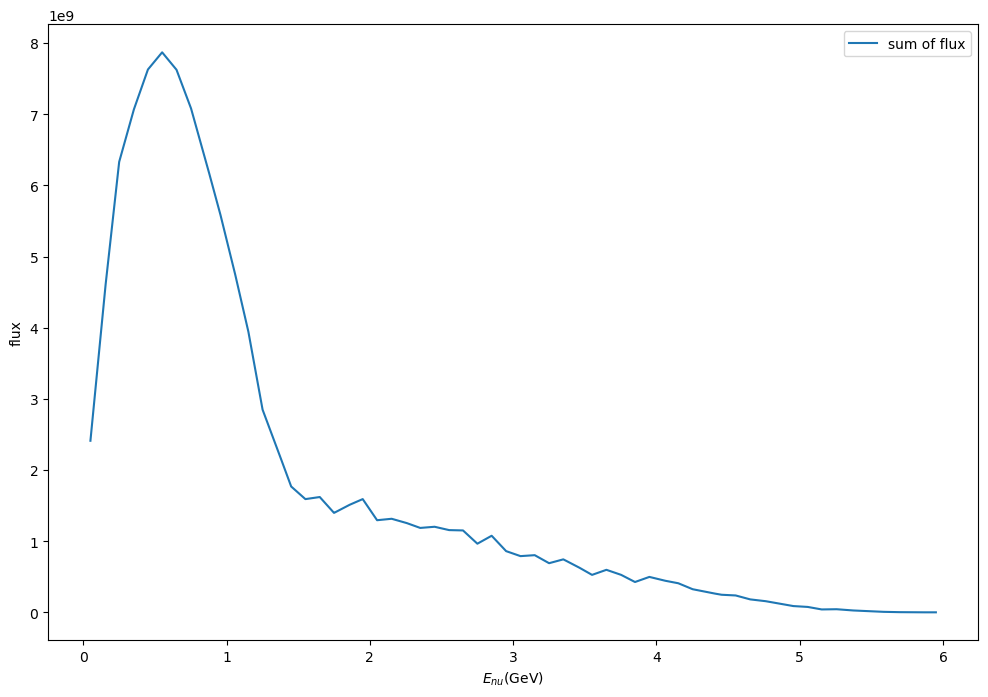

In [31]:
fx = np.linspace(merged_target_flux[:,0][0], merged_target_flux[:,0][-1], fit_lst_leng)
fy = sum_merged_flux_nu_E(fx, *pars_merged) #calculate fitted function values

plt.plot(fx, fy,label='sum of flux')
plt.xlabel('$E_{nu}$(GeV)')
plt.ylabel('flux')
plt.legend()

plt.show()

original flux bin number : 220
new bin merged flux bin number : 74


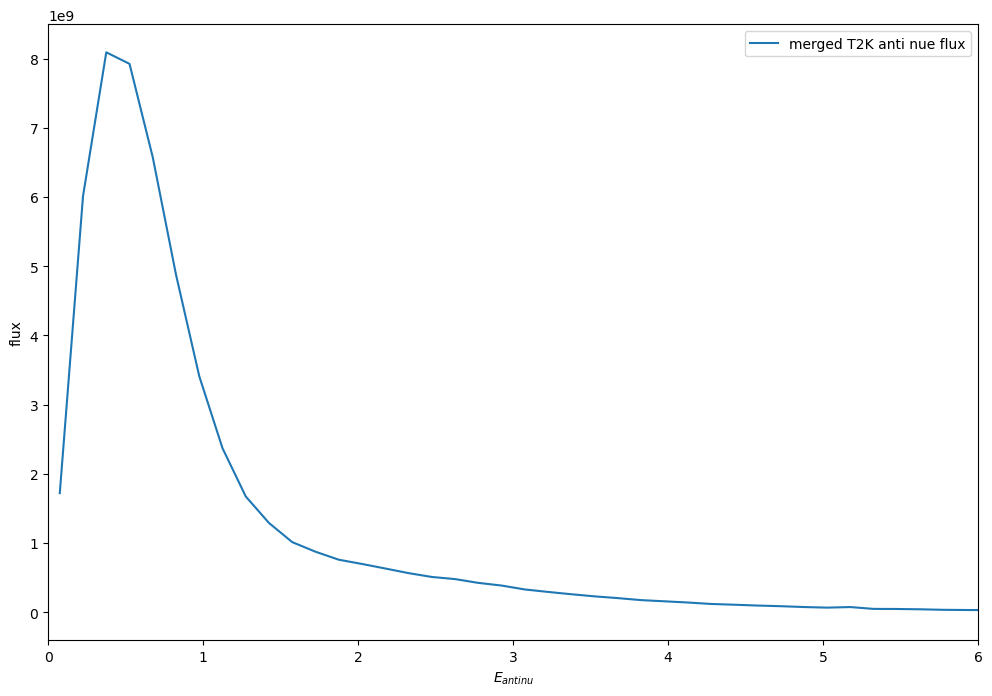

In [32]:
merged_target_anti_nue_flux = merge_bins(target_anti_nue_flux,3)
plt.plot(merged_target_anti_nue_flux[:,0], merged_target_anti_nue_flux[:,1],label='merged T2K anti nue flux')
plt.xlim(0,6)
plt.xlabel("$E_{anti nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

In [33]:
merged_target_anti_nue_flux[:,1]**0.5

array([41484.93702538, 77545.68545918, 89944.42728708, 89013.107649  ,
       81076.09594284, 69833.13444681, 58395.20528263, 48682.64577855,
       40906.39721771, 35916.56999214, 31838.13227353, 29586.03274069,
       27568.09750418, 26432.3034688 , 25159.49125082, 23797.75899814,
       22605.30911091, 21908.90230021, 20623.61106434, 19672.31557291,
       18175.07450695, 17165.85758611, 16165.80753731, 15187.71433319,
       14329.45684014, 13279.05619136, 12622.73081917, 11916.37528781,
       11000.        , 10488.0884817 ,  9889.38825206,  9410.98648743,
        8744.52209481,  8230.02632641,  8725.44172712,  7042.72674466,
        6942.62198308,  6615.63803927,  6024.94813256,  5776.38872191,
        5712.559263  ,  4986.64884132,  4861.41268906,  4661.90232988,
        4501.85147097,  3890.15852291,  3728.27037646,  3321.14438108,
        3568.37965095,  3400.49016075,  3244.99614792,  3087.60964718,
        2783.28343269,  3286.33534503,  2505.32765655,  2224.85954613,
      

In [34]:
sigma_array = np.zeros(len(merged_target_anti_nue_flux[:,1]))
sigma_array = merged_target_anti_nue_flux[:,1]**0.5
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
#sigma_array = 1

pars_anti_nue_merged, cov_anti_nue_merged=optimize.curve_fit(sum_merged_flux_nu_E, merged_target_anti_nue_flux[:,0], merged_target_anti_nue_flux[:,1], p0=[-1/6, 1/6, -1/6, 1/6, 1/6, -1/6],sigma=sigma_array)#, sigma=merged_target_anti_nue_flux[:,1]**0.5) #fit
print("coeff is : "+str(pars_anti_nue_merged))
print("Uncertainty is : "+str(np.sqrt(cov_anti_nue_merged.diagonal())))

coeff is : [ 3.35690311e+02 -3.35211936e+02 -1.06646147e-02  2.73380610e-02
 -3.37931108e-02  3.55694379e-02]
Uncertainty is : [3.08078511e+06 3.08078511e+06 1.00113899e-02 1.75055342e-02
 1.86424496e-02 9.82096310e-03]


coeff is : [ 3.35690311e+02 -3.35211936e+02 -1.06646147e-02  2.73380610e-02
 -3.37931108e-02  3.55694379e-02]
Uncertainty is : [3.08078511e+06 3.08078511e+06 1.00113899e-02 1.75055342e-02
 1.86424496e-02 9.82096310e-03]
target flux $E_{nu}$ avg : 0.9955388360766745 GeV fit flux $E_{nu}$ avg : 0.9918654902384215 GeV
RMS of bin diff : 1.8777E+09
chi^2 of bin diff : 6.7992E+03


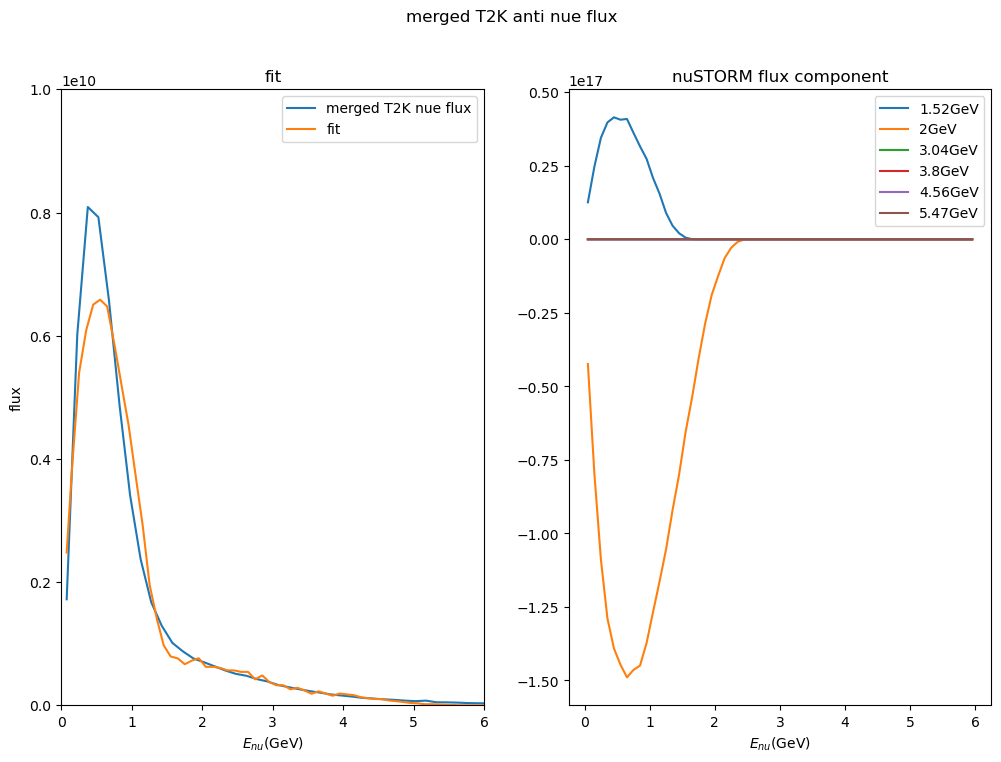

In [35]:
fit_lst_leng = 5000
fx = np.linspace(merged_target_anti_nue_flux[:,0][0], merged_target_anti_nue_flux[:,0][-1], fit_lst_leng)
fy = sum_merged_flux_nu_E(fx, *pars_anti_nue_merged) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(merged_target_anti_nue_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars_anti_nue_merged))
print("Uncertainty is : "+str(np.sqrt(cov_anti_nue_merged.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

merged_anti_nue_diff = bin_dif_RMS(merged_target_anti_nue_flux, fit_flux)
print("RMS of bin diff : "+str("{0:.4E}".format(merged_anti_nue_diff)))

nue_diff = chi_2_hist(merged_target_anti_nue_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('merged T2K anti nue flux')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(merged_target_anti_nue_flux[:,0], merged_target_anti_nue_flux[:,1],label='merged T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst_merged[i][:,0], nuSTORM_flux_lst_merged[i][:,1]*pars_anti_nue_merged[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1e10)
ax1.legend()
ax2.legend()
plt.show()

In [36]:
bin_merge_num = 4

nuFlux1p52_flux_merged = merge_bins(nuFlux1p52_flux, bin_merge_num)
nuFlux2p0_flux_merged = merge_bins(nuFlux2p0_flux, bin_merge_num)
nuFlux3p04_flux_merged = merge_bins(nuFlux3p04_flux, bin_merge_num)
nuFlux3p8_flux_merged = merge_bins(nuFlux3p8_flux, bin_merge_num)
nuFlux4p56_flux_merged = merge_bins(nuFlux4p56_flux, bin_merge_num)
nuFlux5p47_flux_merged = merge_bins(nuFlux5p47_flux, bin_merge_num)

nuSTORM_flux_lst_merged = [nuFlux1p52_flux_merged, nuFlux2p0_flux_merged, nuFlux3p04_flux_merged, nuFlux3p8_flux_merged, nuFlux4p56_flux_merged, nuFlux5p47_flux_merged]

original flux bin number : 120
new bin merged flux bin number : 30
original flux bin number : 120
new bin merged flux bin number : 30
original flux bin number : 120
new bin merged flux bin number : 30
original flux bin number : 120
new bin merged flux bin number : 30
original flux bin number : 120
new bin merged flux bin number : 30
original flux bin number : 120
new bin merged flux bin number : 30


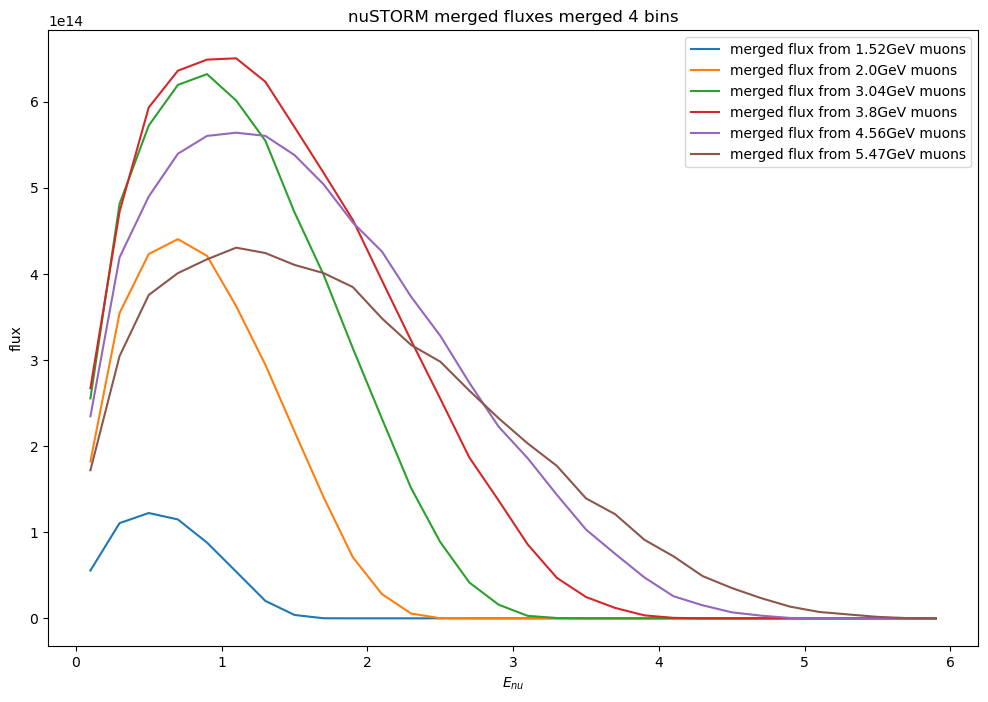

In [37]:
plt.plot(nuFlux1p52_flux_merged[:,0], nuFlux1p52_flux_merged[:,1],label='merged flux from 1.52GeV muons')
plt.plot(nuFlux2p0_flux_merged[:,0], nuFlux2p0_flux_merged[:,1],label='merged flux from 2.0GeV muons')
plt.plot(nuFlux3p04_flux_merged[:,0], nuFlux3p04_flux_merged[:,1],label='merged flux from 3.04GeV muons')
plt.plot(nuFlux3p8_flux_merged[:,0], nuFlux3p8_flux_merged[:,1],label='merged flux from 3.8GeV muons')
plt.plot(nuFlux4p56_flux_merged[:,0], nuFlux4p56_flux_merged[:,1],label='merged flux from 4.56GeV muons')
plt.plot(nuFlux5p47_flux_merged[:,0], nuFlux5p47_flux_merged[:,1],label='merged flux from 5.47GeV muons')

plt.title("nuSTORM merged fluxes merged "+str(bin_merge_num)+" bins")
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

In [38]:
sigma_array = np.zeros(len(merged_target_flux[:,1]))
sigma_array = merged_target_flux[:,1]**0.5
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
#sigma_array = 1

pars_merged, cov_merged=optimize.curve_fit(sum_merged_flux_nu_E, merged_target_flux[:,0], merged_target_flux[:,1], p0=[1/6, 1/6, 1/6, 1/6, 1/6, 1/6],sigma=sigma_array) #fits the whole range with a function with 3 peaks
print("coeff is : "+str(pars_merged))
print("Uncertainty is : "+str(np.sqrt(cov_merged.diagonal())))

coeff is : [-2.74260531e+02  2.74788382e+02 -2.62629786e-02  6.89452365e-02
 -1.02115309e-01  1.01720875e-01]
Uncertainty is : [4.27769186e+06 4.27769183e+06 2.25367200e-02 4.19511830e-02
 4.59028561e-02 2.40870503e-02]


coeff is : [-2.74260531e+02  2.74788382e+02 -2.62629786e-02  6.89452365e-02
 -1.02115309e-01  1.01720875e-01]
Uncertainty is : [4.27769186e+06 4.27769183e+06 2.25367200e-02 4.19511830e-02
 4.59028561e-02 2.40870503e-02]
target flux $E_{nu}$ avg : 1.2212149383610662 GeV fit flux $E_{nu}$ avg : 1.2332676846386974 GeV
RMS of bin diff : 3.1440E+09
chi^2 of bin diff : 5.9989E+03


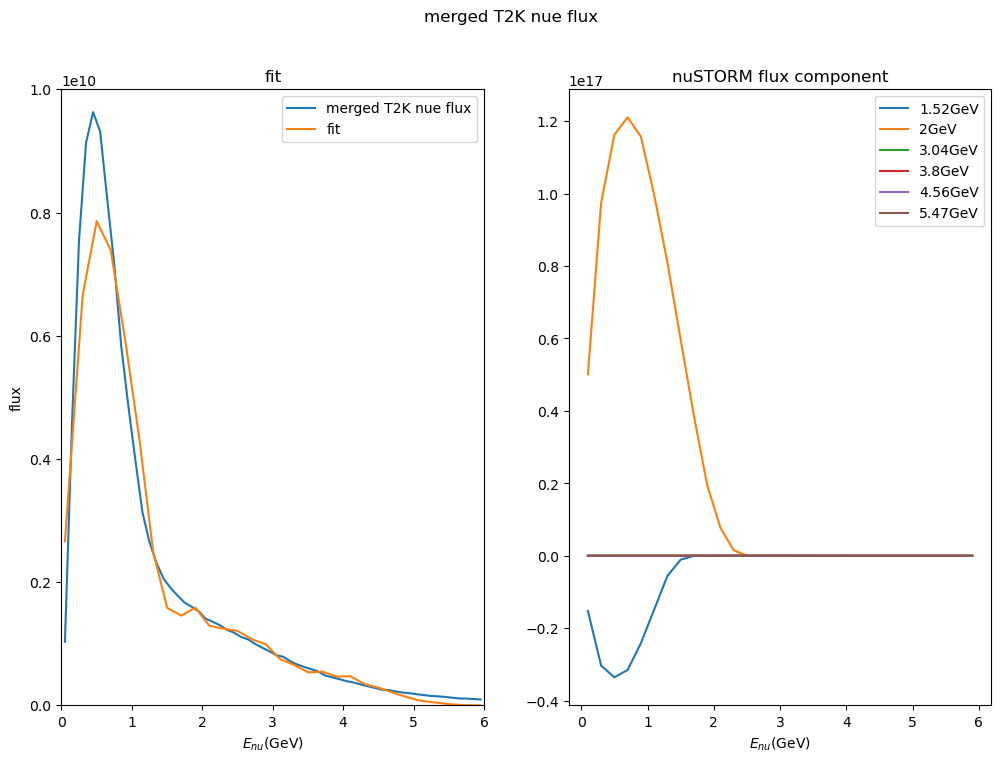

In [39]:
fit_lst_leng = 5000
fx = np.linspace(merged_target_flux[:,0][0], merged_target_flux[:,0][-1], fit_lst_leng)
fy = sum_merged_flux_nu_E(fx, *pars_merged) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(merged_target_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars_merged))
print("Uncertainty is : "+str(np.sqrt(cov_merged.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

merged_nue_diff = bin_dif_RMS(merged_target_flux, fit_flux)
print("RMS of bin diff : "+str("{0:.4E}".format(merged_nue_diff)))

nue_diff = chi_2_hist(merged_target_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('merged T2K nue flux')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(merged_target_flux[:,0], merged_target_flux[:,1],label='merged T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst_merged[i][:,0], nuSTORM_flux_lst_merged[i][:,1]*pars_merged[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1e10)
ax1.legend()
ax2.legend()
plt.show()

In [40]:
sigma_array = np.zeros(len(merged_target_anti_nue_flux[:,1]))
sigma_array = merged_target_anti_nue_flux[:,1]**0.5
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
#sigma_array = 1

pars_anti_nue_merged, cov_anti_nue_merged=optimize.curve_fit(sum_merged_flux_nu_E, merged_target_anti_nue_flux[:,0], merged_target_anti_nue_flux[:,1], p0=[1/6, 1/6, 1/6, 1/6, 1/6, 1/6],sigma=sigma_array) #fits the whole range with a function with 3 peaks
print("coeff is : "+str(pars_anti_nue_merged))
print("Uncertainty is : "+str(np.sqrt(cov_anti_nue_merged.diagonal())))

coeff is : [-3.38947135e+02  3.39438033e+02 -1.58971706e-02  3.60925995e-02
 -4.28686855e-02  3.98169845e-02]
Uncertainty is : [3.55476765e+06 3.55476765e+06 1.10475087e-02 1.97456407e-02
 2.11426861e-02 1.09779414e-02]


coeff is : [-3.38947135e+02  3.39438033e+02 -1.58971706e-02  3.60925995e-02
 -4.28686855e-02  3.98169845e-02]
Uncertainty is : [3.55476765e+06 3.55476765e+06 1.10475087e-02 1.97456407e-02
 2.11426861e-02 1.09779414e-02]
target flux $E_{nu}$ avg : 0.9955388360766745 GeV fit flux $E_{nu}$ avg : 0.997721102376631 GeV
RMS of bin diff : 1.8777E+09
chi^2 of bin diff : 6.7992E+03


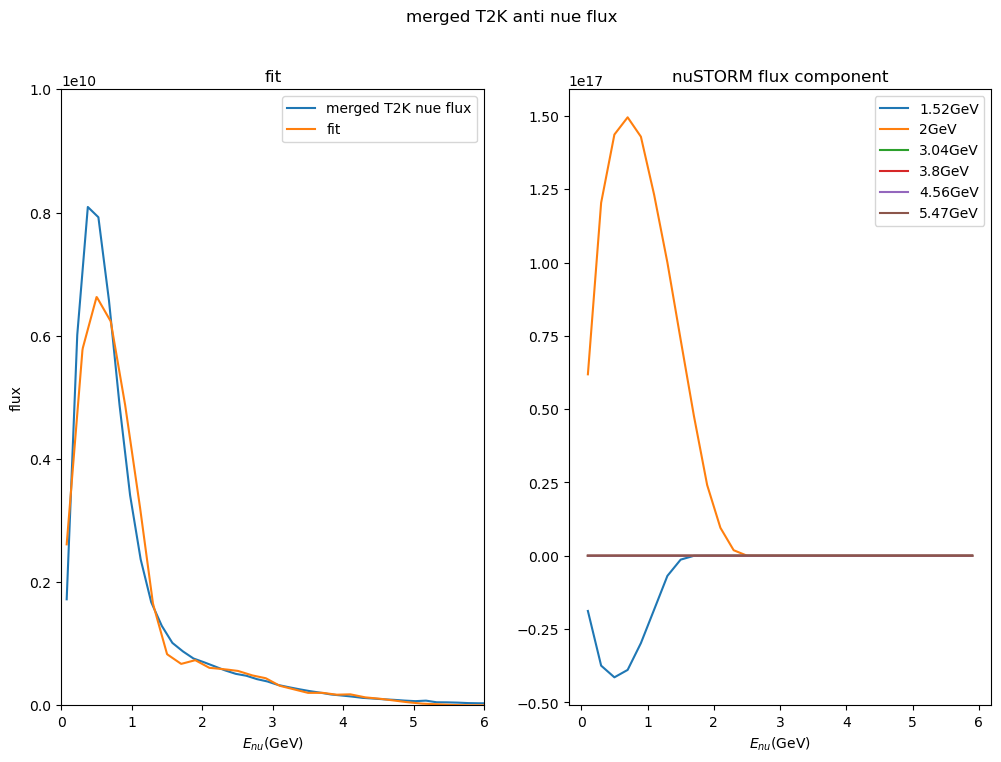

In [41]:
fit_lst_leng = 5000
fx = np.linspace(merged_target_anti_nue_flux[:,0][0], merged_target_anti_nue_flux[:,0][-1], fit_lst_leng)
fy = sum_merged_flux_nu_E(fx, *pars_anti_nue_merged) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(merged_target_anti_nue_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars_anti_nue_merged))
print("Uncertainty is : "+str(np.sqrt(cov_anti_nue_merged.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

merged_anti_nue_diff = bin_dif_RMS(merged_target_anti_nue_flux, fit_flux)
print("RMS of bin diff : "+str("{0:.4E}".format(merged_anti_nue_diff)))

nue_diff = chi_2_hist(merged_target_anti_nue_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('merged T2K anti nue flux')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(merged_target_anti_nue_flux[:,0], merged_target_anti_nue_flux[:,1],label='merged T2K nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst_merged[i][:,0], nuSTORM_flux_lst_merged[i][:,1]*pars_anti_nue_merged[i],label=E_lst[i])

ax1.set_xlim(0,6)
ax1.set_ylim(0,1e10)
ax1.legend()
ax2.legend()
plt.show()

In [42]:
DUNE_nue_numode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_numode.dat")
DUNE_nue_antinumode_flux = read_flux("nuSTORM_flux_txt_files/DUNE-ND_nueFlux_antinumode.dat")

the number of line of the txt file : nuSTORM_flux_txt_files/DUNE-ND_nueFlux_numode.dat list is : 319
the number of line of the txt file : nuSTORM_flux_txt_files/DUNE-ND_nueFlux_antinumode.dat list is : 319


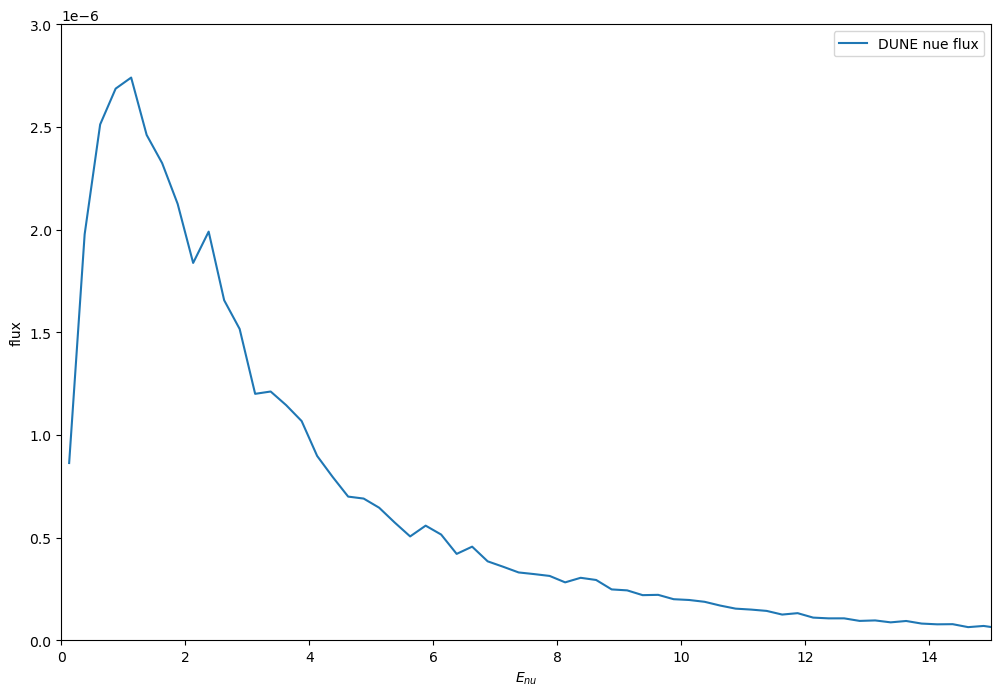

In [43]:
#target_flux = merge_bins(target_flux,2)
plt.plot(DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],label='DUNE nue flux')
plt.xlim(0,15)
plt.ylim(0,3e-6)
plt.xlabel("$E_{nu}$")
plt.ylabel("flux")
plt.legend()
plt.show()

In [44]:
sigma_array = np.zeros(len(DUNE_nue_numode_flux[:,1]))
sigma_array = DUNE_nue_numode_flux[:,1]**0.5
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
#sigma_array = 1

pars, cov=optimize.curve_fit(sum_flux_nu_E, DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1], p0=[1/6, 1/6, 1/6, 1/6, 1/6, 1/6],sigma=sigma_array) #fits the whole range with a function with 3 peaks
print("coeff is : "+str(pars))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

coeff is : [ 8.88643765e-17 -2.70057391e-17 -1.54593224e-17  1.12640238e-16
 -2.25549477e-16  2.17587357e-16]
Uncertainty is : [5.70899776e-17 3.41613834e-17 3.18823846e-17 4.43087177e-17
 5.09114900e-17 2.79886263e-17]


coeff is : [ 8.88643765e-17 -2.70057391e-17 -1.54593224e-17  1.12640238e-16
 -2.25549477e-16  2.17587357e-16]
Uncertainty is : [5.70899776e-17 3.41613834e-17 3.18823846e-17 4.43087177e-17
 5.09114900e-17 2.79886263e-17]
target flux $E_{nu}$ avg : 4.035832532667732 GeV fit flux $E_{nu}$ avg : 2.0109328489277782 GeV
RMS of bin diff : 4.5216E-07
chi^2 of bin diff : 4.3486E-05


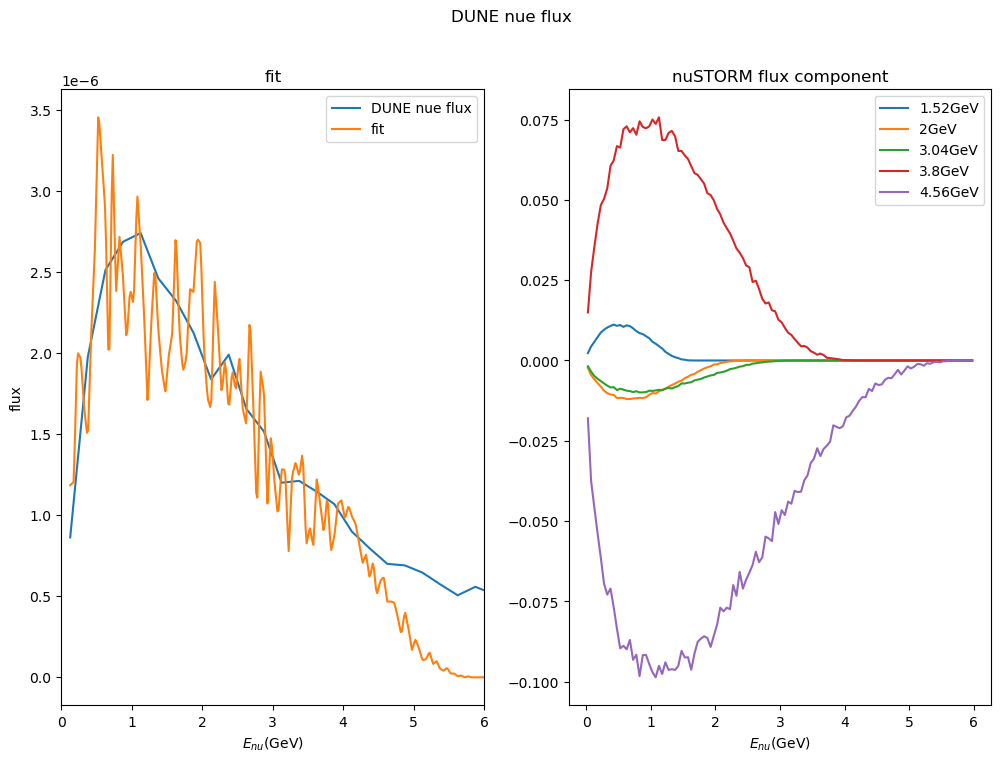

In [45]:
fit_lst_leng = 5000
fx = np.linspace(DUNE_nue_numode_flux[:,0][0], DUNE_nue_numode_flux[:,0][-1], fit_lst_leng)
fy = sum_flux_nu_E(fx, *pars) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(DUNE_nue_numode_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars))
print("Uncertainty is : "+str(np.sqrt(cov.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

nue_diff = bin_dif_RMS(DUNE_nue_numode_flux, fit_flux)
print("RMS of bin diff : "+str("{0:.4E}".format(nue_diff)))

nue_diff = chi_2_hist(DUNE_nue_numode_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DUNE nue flux')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],label='DUNE nue flux')
ax1.plot(fx, fy,label='fit')

nuSTORM_flux_lst = [nuFlux1p52_flux, nuFlux2p0_flux, nuFlux3p04_flux, nuFlux3p8_flux, nuFlux5p47_flux]
for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst[i][:,0], nuSTORM_flux_lst[i][:,1]*pars[i],label=E_lst[i])

ax1.set_xlim(0,6)
#ax1.set_ylim(0,1e8)
ax1.legend()
ax2.legend()
plt.show()

In [57]:
sigma_array = np.zeros(len(DUNE_nue_numode_flux[:,1]))
sigma_array = DUNE_nue_numode_flux[:,1]**0.5
for i in range(0,len(sigma_array)):
    if sigma_array[i] == 0:
        sigma_array[i] = 1
#sigma_array = 1

pars_merged, cov_merged=optimize.curve_fit(sum_merged_flux_nu_E, DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1], p0=[1/6, 1/6, 1/6, 1/6, 1/6, 1/6],sigma=sigma_array) #fits the whole range with a function with 3 peaks
print("coeff is : "+str(pars_merged))
print("Uncertainty is : "+str(np.sqrt(cov_merged.diagonal())))

coeff is : [-1.66500574e+02  1.66500574e+02 -1.86801515e-15 -3.68420689e-15
  8.07714194e-15 -5.08174488e-15]
Uncertainty is : [4.16018296e-07 4.16018297e-07 1.42743633e-15 2.77607475e-15
 3.21198228e-15 1.76847450e-15]


coeff is : [-1.66500574e+02  1.66500574e+02 -1.86801515e-15 -3.68420689e-15
  8.07714194e-15 -5.08174488e-15]
Uncertainty is : [4.16018296e-07 4.16018297e-07 1.42743633e-15 2.77607475e-15
 3.21198228e-15 1.76847450e-15]
target flux $E_{nu}$ avg : 4.035832532667732 GeV fit flux $E_{nu}$ avg : -0.24670185885333987 GeV
RMS of bin diff : 4.5169E-07
chi^2 of bin diff : 4.3426E-05


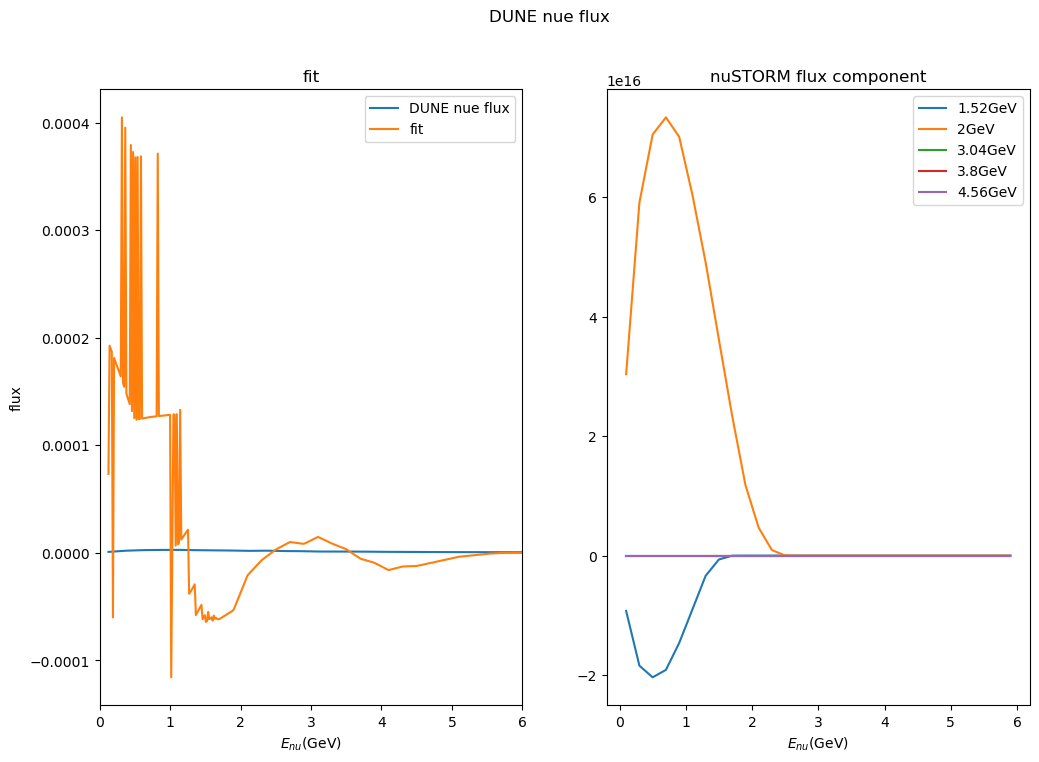

In [58]:
fit_lst_leng = 5000
fx = np.linspace(DUNE_nue_numode_flux[:,0][0], DUNE_nue_numode_flux[:,0][-1], fit_lst_leng)
fy = sum_merged_flux_nu_E(fx, *pars_merged) #calculate fitted function values
fit_flux = np.zeros(2*fit_lst_leng).reshape((fit_lst_leng,2))
for i in range(0,fit_lst_leng):
    fit_flux[i] = [fx[i], fy[i]]
    
target_avg = get_flux_avg(DUNE_nue_numode_flux)
fit_avg = get_flux_avg(fit_flux)
print("coeff is : "+str(pars_merged))
print("Uncertainty is : "+str(np.sqrt(cov_merged.diagonal())))

print("target flux $E_{nu}$ avg : "+str(target_avg)+" GeV fit flux $E_{nu}$ avg : "+str(fit_avg)+" GeV")

merged_nue_diff = bin_dif_RMS(DUNE_nue_numode_flux, fit_flux)
print("RMS of bin diff : "+str("{0:.4E}".format(merged_nue_diff)))

nue_diff = chi_2_hist(DUNE_nue_numode_flux, fit_flux, 0.1)
print("chi^2 of bin diff : "+str("{0:.4E}".format(nue_diff)))

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('DUNE nue flux')

ax1.set(xlabel='$E_{nu}$(GeV)', ylabel='flux')
ax2.set(xlabel='$E_{nu}$(GeV)')

ax1.set_title('fit')
ax2.set_title('nuSTORM flux component')

ax1.plot(DUNE_nue_numode_flux[:,0], DUNE_nue_numode_flux[:,1],label='DUNE nue flux')
ax1.plot(fx, fy,label='fit')

for i in range(0, len(nuSTORM_flux_lst)):
    ax2.plot(nuSTORM_flux_lst_merged[i][:,0], nuSTORM_flux_lst_merged[i][:,1]*pars_merged[i],label=E_lst[i])

ax1.set_xlim(0,6)
#ax1.set_ylim(0,1e8)
ax1.legend()
ax2.legend()
plt.show()